# Домашнє завдання до теми 12 «Метод k-means. Ієрархічний кластерний аналіз»

**Курс:** Вступ до машинного навчання (ІПЗ, 5 семестр)
**Студентка:** Вох Ірина

**Мета:** на наборі даних *Concrete* (рецептури бетону) створити нову ознаку `Components`, нормалізувати дані,
визначити оптимальну кількість кластерів за «правилом ліктя» (`KElbowVisualizer`), виконати кластеризацію методом
k-середніх і побудувати описовий «звіт» по кластерах (медіани ознак + кількість рецептур), після чого зробити висновки
про фактори, що впливають на міцність бетону.

**План роботи:**
1. Імпорт бібліотек.
2. Завантаження набору даних Concrete (як у темі 10).
3. Короткий огляд даних.
4. Створення ознаки `Components` прийомом підрахунку кількості.
5. Нормалізація даних (`StandardScaler`).
6. Визначення оптимальної кількості кластерів (`KElbowVisualizer`).
7. Кластеризація методом k-середніх та отримання міток.
8. Візуалізація та оцінка якості кластеризації (додатково).
9. Звіт по кластерах: медіани ознак (на оригінальних даних) + кількість об'єктів.
10. Аналіз звіту та висновки.

## 1. Імпорт бібліотек

In [1]:
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram
from yellowbrick.cluster import KElbowVisualizer

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)

## 2. Завантаження набору даних

Набір даних Concrete завантажуємо так само, як у розділі «Поширені прийоми генерації ознак. Математичні перетворення»
теми 10: з об'єкта-словника, збереженого у файлі `mod_05_topic_10_various_data.pkl`.

In [2]:
with open('../datasets/mod_05_topic_10_various_data.pkl', 'rb') as fl:
    datasets = pickle.load(fl)

concrete = datasets['concrete'].copy()
concrete.head()

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,CompressiveStrength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 3. Огляд даних

In [3]:
print('Розмір набору:', concrete.shape)
concrete.info()

Розмір набору: (1030, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Cement               1030 non-null   float64
 1   BlastFurnaceSlag     1030 non-null   float64
 2   FlyAsh               1030 non-null   float64
 3   Water                1030 non-null   float64
 4   Superplasticizer     1030 non-null   float64
 5   CoarseAggregate      1030 non-null   float64
 6   FineAggregate        1030 non-null   float64
 7   Age                  1030 non-null   int64  
 8   CompressiveStrength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [4]:
print('Пропущені значення:\n', concrete.isna().sum(), sep='')
print('\nКількість повних дублікатів рядків:', concrete.duplicated().sum())

Пропущені значення:
Cement                 0
BlastFurnaceSlag       0
FlyAsh                 0
Water                  0
Superplasticizer       0
CoarseAggregate        0
FineAggregate          0
Age                    0
CompressiveStrength    0
dtype: int64

Кількість повних дублікатів рядків: 25


In [5]:
concrete.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
BlastFurnaceSlag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
FlyAsh,1030.0,54.19,64.00,0.00,0.00,0.00,118.30,200.1
Water,1030.0,181.57,21.35,121.80,164.90,185.00,192.00,247.0
Superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.40,10.20,32.2
CoarseAggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
FineAggregate,1030.0,773.58,80.18,594.00,730.95,779.50,824.00,992.6
Age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
CompressiveStrength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


Набір містить 1030 рецептур бетону: вміст 7 складових (кг/м³), вік зразка `Age` (дні) та цільову характеристику
`CompressiveStrength` (міцність на стиск, МПа). Усі ознаки числові, пропусків немає. Дублікати (якщо є) — це
однакові рецептури, випробувані повторно; вони є легітимними спостереженнями, тож ми їх не видаляємо.
Ознаки мають дуже різні масштаби (наприклад, `CoarseAggregate` ~1000, `Superplasticizer` ~6), тому перед
кластеризацією (алгоритм k-means спирається на евклідову відстань) їх обов'язково треба нормалізувати.

## 4. Нова ознака `Components` (прийом підрахунку кількості)

Частина рецептур не містить окремих складових (їх вміст дорівнює 0). Перетворимо числові ознаки складових на булеві
методом `gt(0)` і підсумуємо по рядку — отримаємо кількість задіяних складових у кожній рецептурі.

In [6]:
components = ['Cement',
              'BlastFurnaceSlag',
              'FlyAsh',
              'Water',
              'Superplasticizer',
              'CoarseAggregate',
              'FineAggregate']

concrete['Components'] = concrete[components].gt(0).sum(axis=1)

concrete[components + ['Components']].head(10)

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Components
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,5
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,5
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,5
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,5
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,5
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,5
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,5
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,5
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,5
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,4


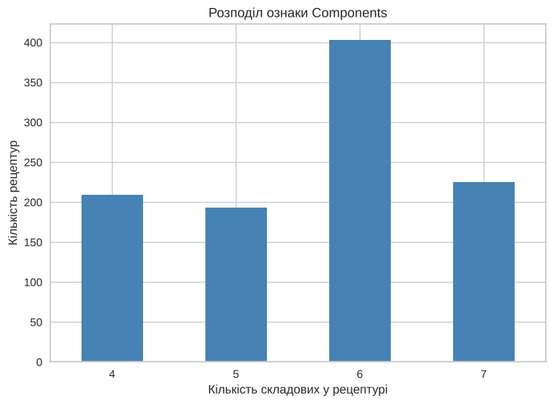

In [7]:
ax = concrete['Components'].value_counts().sort_index().plot.bar(rot=0, color='steelblue')
ax.set_xlabel('Кількість складових у рецептурі')
ax.set_ylabel('Кількість рецептур')
ax.set_title('Розподіл ознаки Components')
plt.show()

Рецептури містять від 4 до 7 складових. Цемент, вода та обидва заповнювачі присутні завжди, тож мінімум — 4
(«базовий» бетон без добавок), а різниця між рецептурами визначається наявністю шлаку, золи-винесення та
суперпластифікатора.

## 5. Нормалізація даних та вибір ознак

Кластеризуємо бетони **за складом і віком**, а цільову характеристику `CompressiveStrength`
(міцність на стиск) до ознак кластеризації **не включаємо**: це результат випробування, а не
параметр рецептури, тож міцність аналізуємо вже як властивість готових кластерів (інакше
кластери «підлаштувалися» б під цільову змінну). Решту ознак (включно з новою `Components`)
нормалізуємо `StandardScaler` (середнє 0, стандартне відхилення 1), бо k-means спирається на
евклідову відстань. Оригінальний датафрейм `concrete` залишаємо без змін — він знадобиться для
побудови звіту.

In [8]:
scaler = StandardScaler()

# Міцність — цільова характеристика, а не ознака рецептури, тож виключаємо її з кластеризації.
features = concrete.columns.drop('CompressiveStrength')

X = pd.DataFrame(scaler.fit_transform(concrete[features]),
                 columns=features,
                 index=concrete.index)

X.describe().T[['mean', 'std']].round(3)

,mean,std
Cement,-0.0,1.0
BlastFurnaceSlag,-0.0,1.0
FlyAsh,-0.0,1.0
Water,-0.0,1.0
Superplasticizer,-0.0,1.0
CoarseAggregate,0.0,1.0
FineAggregate,-0.0,1.0
Age,0.0,1.0
Components,0.0,1.0


## 6. Визначення оптимальної кількості кластерів (`KElbowVisualizer`)

Виконуємо серію кластеризацій k-means для k від 2 до 9 та будуємо графік залежності сумарної міри щільності
(distortion — сума квадратів відстаней до центроїдів) від k. Оптимальне k визначаємо за «правилом ліктя».

> **Технічна примітка.** У новіших версіях scikit-learn (≥ 1.6) змінився механізм визначення типу моделі, і
> `yellowbrick` 1.5 перестав розпізнавати `KMeans` як кластеризатор. Тому для візуалізатора використовуємо
> тонкий підклас `KMeans` з явно заданим атрибутом `_estimator_type = 'clusterer'`. Алгоритм і параметри при цьому
> не змінюються; у середовищі курсу код працює так само.

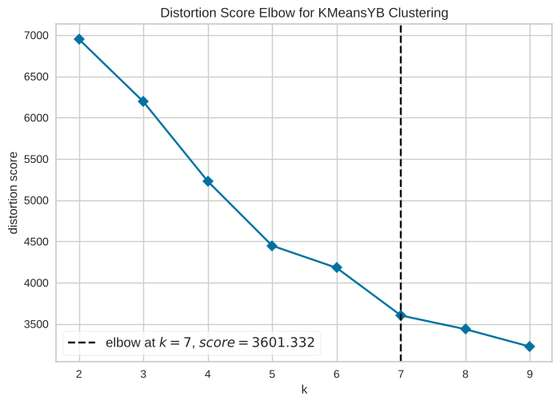

Оптимальна кількість кластерів за правилом ліктя: 7


In [9]:
class KMeansYB(KMeans):
    # сумісність yellowbrick 1.5 з новими версіями scikit-learn
    _estimator_type = 'clusterer'


model_kmn = KMeansYB(random_state=42)

visualizer = KElbowVisualizer(
    model_kmn,
    k=(2, 10),
    timings=False)

visualizer.fit(X)
visualizer.show()

n_clusters = visualizer.elbow_value_
print('Оптимальна кількість кластерів за правилом ліктя:', n_clusters)

In [10]:
pd.Series(visualizer.k_scores_, index=range(2, 10), name='distortion').round(1).to_frame().T

,2,3,4,5,6,7,8,9
distortion,6949.3,6192.6,5227.8,4447.1,4179.1,3601.3,3435.4,3224.6


## 7. Кластеризація методом k-середніх

Проводимо кластеризацію з кількістю кластерів, визначеною на попередньому кроці, і отримуємо мітки.

In [11]:
k_means = KMeans(n_clusters=n_clusters, random_state=42)
labels = k_means.fit_predict(X)

print('Мітки перших 20 об\'єктів:', labels[:20])
pd.Series(labels).value_counts().sort_index().rename('Count').to_frame().T

Мітки перших 20 об'єктів: [3 3 2 2 2 1 2 3 1 3 1 1 2 1 1 6 1 2 3 2]


,0,1,2,3,4,5,6
Count,144,178,42,46,292,152,176


## 8. Візуалізація та оцінка якості кластеризації (додатково)

Щоб переконатися, що кластери змістовні, обчислимо коефіцієнт силуету для різних k та відобразимо кластери в
просторі двох перших головних компонент (PCA, тема 11).

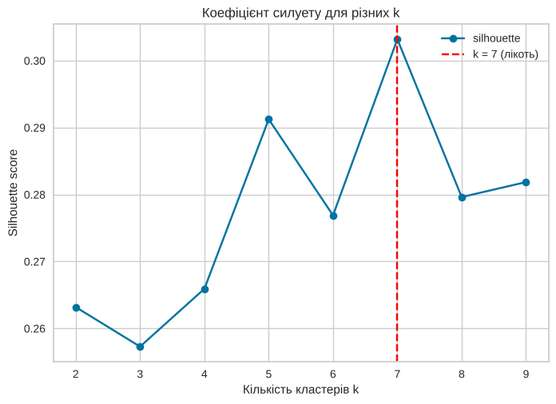

Silhouette score для k = 7: 0.303


In [12]:
sil = {k: silhouette_score(X, KMeans(n_clusters=k, random_state=42).fit_predict(X))
       for k in range(2, 10)}
sil = pd.Series(sil, name='silhouette')

ax = sil.plot(marker='o')
ax.axvline(n_clusters, ls='--', color='red', label=f'k = {n_clusters} (лікоть)')
ax.set_xlabel('Кількість кластерів k')
ax.set_ylabel('Silhouette score')
ax.set_title('Коефіцієнт силуету для різних k')
ax.legend()
plt.show()

print(f'Silhouette score для k = {n_clusters}: {sil[n_clusters]:.3f}')

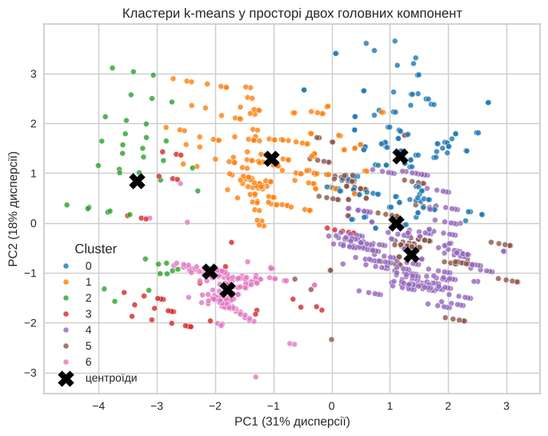

In [13]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels,
                palette='tab10', s=25, alpha=0.8, ax=ax)
centers_pca = pca.transform(pd.DataFrame(k_means.cluster_centers_, columns=X.columns))
ax.scatter(centers_pca[:, 0], centers_pca[:, 1], c='black', marker='X', s=200, label='центроїди')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} дисперсії)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} дисперсії)')
ax.set_title('Кластери k-means у просторі двох головних компонент')
ax.legend(title='Cluster')
plt.show()

Для порівняння побудуємо також ієрархічну структуру кластерів за допомогою `AgglomerativeClustering`
(метод Варда) та дендрограму — так, як це показано у практичній частині теми 12.

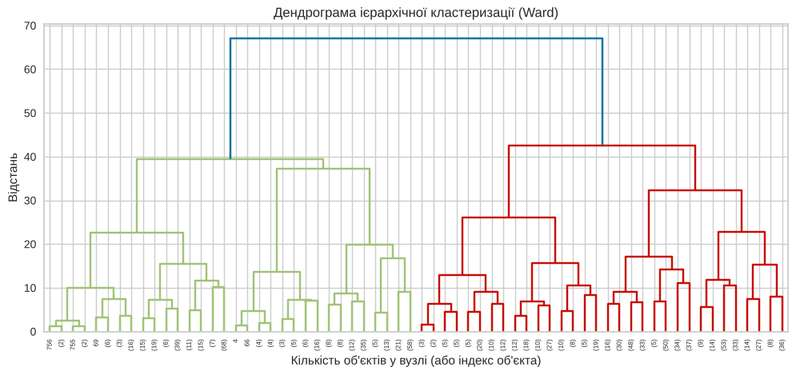

Adjusted Rand Index (k-means vs ієрархічна, k = 7): 0.668


In [14]:
def plot_dendrogram(model, **kwargs):

    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]).astype(float)

    dendrogram(linkage_matrix, **kwargs)


model_agg = AgglomerativeClustering(distance_threshold=0,
                                    n_clusters=None,
                                    linkage='ward')
model_agg = model_agg.fit(X)

plt.figure(figsize=(12, 5))
plot_dendrogram(model_agg, truncate_mode='level', p=5)
plt.title('Дендрограма ієрархічної кластеризації (Ward)')
plt.xlabel('Кількість об\'єктів у вузлі (або індекс об\'єкта)')
plt.ylabel('Відстань')
plt.show()

agg_labels = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward').fit_predict(X)
print(f'Adjusted Rand Index (k-means vs ієрархічна, k = {n_clusters}): '
      f'{adjusted_rand_score(labels, agg_labels):.3f}')

## 9. Звіт по кластерах

Для звіту використовуємо **оригінальні (ненормалізовані) дані**: додаємо мітки кластерів, групуємо методом
`groupby` і рахуємо медіани всіх ознак (включно з `Components`), а потім додаємо кількість рецептур у кожному кластері.

In [15]:
report = (concrete
          .assign(Cluster=labels)
          .groupby('Cluster')
          .median())

report['Count'] = (pd.Series(labels, index=concrete.index)
                   .value_counts()
                   .sort_index())

report.round(1)

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,CompressiveStrength,Components,Count
Cluster,,,,,,,,,,,
0,255.2,107.8,123.0,193.0,8.5,873.6,750.0,28.0,32.9,7.0,144
1,192.0,183.9,0.0,192.0,0.0,965.4,746.4,28.0,28.0,5.0,178
2,332.5,47.5,0.0,228.0,0.0,932.0,670.0,270.0,43.4,5.0,42
3,500.0,0.0,0.0,189.0,0.0,1125.0,613.0,28.0,49.7,4.0,46
4,213.7,0.0,121.6,166.6,8.1,1014.3,792.7,28.0,33.7,6.0,292
5,387.0,117.2,0.0,160.0,11.6,931.0,803.7,28.0,55.5,6.0,152
6,331.0,0.0,0.0,192.0,0.0,1003.5,789.0,28.0,25.1,4.0,176


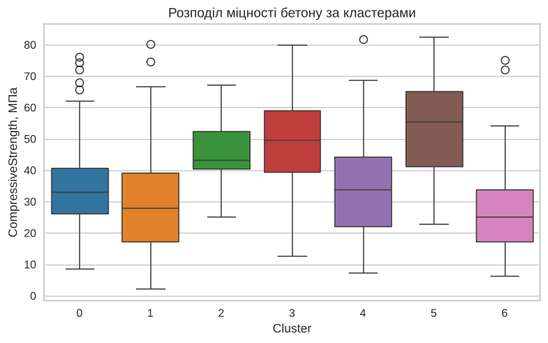

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(x=labels, y=concrete['CompressiveStrength'], palette='tab10', ax=ax)
ax.set_xlabel('Cluster')
ax.set_ylabel('CompressiveStrength, МПа')
ax.set_title('Розподіл міцності бетону за кластерами')
plt.show()

Додатково (для інтерпретації) порахуємо медіанне водоцементне відношення та частку рецептур із
суперпластифікатором у кожному кластері — це класичні технологічні фактори міцності бетону.

In [17]:
extra = (concrete
         .assign(Cluster=labels,
                 WaterCementRatio=concrete['Water'] / concrete['Cement'],
                 HasSuperplasticizer=concrete['Superplasticizer'].gt(0))
         .groupby('Cluster')
         .agg(WaterCementRatio=('WaterCementRatio', 'median'),
              ShareWithSuperplasticizer=('HasSuperplasticizer', 'mean'),
              MeanStrength=('CompressiveStrength', 'mean')))

extra.round(2)

,WaterCementRatio,ShareWithSuperplasticizer,MeanStrength
Cluster,,,
0,0.77,1.00,34.20
1,1.00,0.26,28.67
2,0.67,0.00,45.22
3,0.40,0.33,49.88
4,0.77,0.98,33.90
5,0.41,1.00,53.49
6,0.58,0.03,26.38


## 10. Аналіз звіту та висновки

In [18]:
for c, row in report.sort_values('CompressiveStrength', ascending=False).iterrows():
    print(f"Кластер {c}: {int(row['Count'])} рецептур, медіанна міцність {row['CompressiveStrength']:.1f} МПа, "
          f"цемент {row['Cement']:.0f}, вода {row['Water']:.0f}, суперпластифікатор {row['Superplasticizer']:.1f}, "
          f"вік {row['Age']:.0f} дн., складових {row['Components']:.0f}")

Кластер 5: 152 рецептур, медіанна міцність 55.5 МПа, цемент 387, вода 160, суперпластифікатор 11.6, вік 28 дн., складових 6
Кластер 3: 46 рецептур, медіанна міцність 49.7 МПа, цемент 500, вода 189, суперпластифікатор 0.0, вік 28 дн., складових 4
Кластер 2: 42 рецептур, медіанна міцність 43.4 МПа, цемент 332, вода 228, суперпластифікатор 0.0, вік 270 дн., складових 5
Кластер 4: 292 рецептур, медіанна міцність 33.7 МПа, цемент 214, вода 167, суперпластифікатор 8.1, вік 28 дн., складових 6
Кластер 0: 144 рецептур, медіанна міцність 32.9 МПа, цемент 255, вода 193, суперпластифікатор 8.5, вік 28 дн., складових 7
Кластер 1: 178 рецептур, медіанна міцність 28.0 МПа, цемент 192, вода 192, суперпластифікатор 0.0, вік 28 дн., складових 5
Кластер 6: 176 рецептур, медіанна міцність 25.1 МПа, цемент 331, вода 192, суперпластифікатор 0.0, вік 28 дн., складових 4


### Висновки

**Щодо процесу.** Набір Concrete (1030 рецептур, без пропусків) доповнено ознакою `Components`
(4–7 складових у рецептурі), дані нормалізовано `StandardScaler`. **Цільову характеристику
`CompressiveStrength` виключено з ознак кластеризації** — міцність є результатом випробування, а не
параметром рецептури, тож бетони групуємо за складом і віком, а міцність аналізуємо вже як
властивість готових кластерів (так уникаємо «витоку» цільової змінної в структуру кластерів). За
«правилом ліктя» (`KElbowVisualizer`, k = 2…9) оптимальна кількість кластерів — **7**; коефіцієнт
силуету для k = 7 (≈ 0.30) — один із найвищих серед розглянутих k. Кластери частково перекриваються
(силует < 0.5 — типово для «неперервних» рецептурних даних), але мають чітку технологічну
інтерпретацію. Ієрархічна кластеризація (Ward) дає подібне розбиття (ARI ≈ 0.67), що підтверджує
стійкість знайденої структури.

**Опис кластерів (за медіанами звіту, відсортовано за міцністю):**

| Кластер | Рецептур | Характеристика | Медіанна міцність |
|---|---|---|---|
| 5 | 152 | Багато цементу (387), **мало води (160)**, **багато суперпластифікатора (11.6)**, 6 складових, **найнижче В/Ц (0.41)** | **≈ 55.5 МПа — найміцніший** |
| 3 | 46 | **Дуже багато цементу (500)**, низьке В/Ц (0.40), але **без суперпластифікатора**, лише 4 складові | ≈ 49.7 МПа |
| 2 | 42 | **«Старі» зразки (вік ~270 днів)**, цемент 332, багато води (228), без добавок | ≈ 43.4 МПа |
| 4 | 292 | Найбільший кластер: помірно цементу (214), **зола-винесення (122)** + суперпластифікатор, 6 складових | ≈ 33.7 МПа |
| 0 | 144 | **Усі 7 складових**: цемент (255), шлак, зола й суперпластифікатор разом | ≈ 32.9 МПа |
| 1 | 178 | **Багато шлаку (184)**, мало цементу (192), без суперпластифікатора, **найвище В/Ц (1.00)** | ≈ 28.0 МПа |
| 6 | 176 | «Базовий» бетон із **4 складових** (цемент 331, вода, заповнювачі), без добавок | ≈ 25.1 МПа — найслабший |

**Фактори, що впливають на міцність (аналізуємо вже за готовими кластерами):**

1. **Водоцементне відношення (В/Ц).** Найміцніший кластер 5 має одне з найнижчих В/Ц (≈ 0.41), а кластери
   з високим В/Ц (1 — ≈ 1.00) — серед найслабших. Водночас саме низьке В/Ц не гарантує максимуму: кластер 3
   має багато цементу (500) і низьке В/Ц (0.40), але без суперпластифікатора поступається кластеру 5.
2. **Суперпластифікатор** дозволяє зменшити воду без втрати рухливості суміші: три найсильніші «молоді»
   (28 днів) кластери з ним (5, 4, 0) міцніші за «базові» рецептури без добавок (6, 1).
3. **Вік зразка.** Кластер 2 виділяється переважно віком: попри велику кількість води, тривале тверднення
   (~270 днів) дає третю за величиною міцність. Тобто `Age` — важливий фактор при порівнянні рецептур.
4. **Мінеральні добавки (шлак, зола)** частково замінюють цемент: рецептури з високою часткою шлаку при
   малій кількості цементу (кластер 1) мають низьку міцність у віці 28 днів.
5. **Кількість складових (`Components`)**: «прості» 4-компонентні рецептури без добавок (кластер 6) —
   найменш міцні, а найсильніші «молоді» кластери — 6-компонентні. Отже, нова ознака інформативна для
   подальшого моделювання.

**Практичне значення.** Оскільки кластери побудовано **лише за складом і віком** (без цільової змінної), їх
можна використати як незалежну категоріальну ознаку в задачі прогнозування `CompressiveStrength` без ризику
витоку інформації, а також для пошуку «типових» рецептур високоміцного бетону (кластер 5: багато цементу, мало
води, суперпластифікатор).